In [1]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.sparse as sp
import scipy.sparse.linalg as spla

# Wavelength (micrometers)
wavelength = 1.55
k0 = 2 * np.pi / wavelength

# Refractive indices
n_core = 3.48
n_clad = 1.44

# Slab width (micrometers)
width = 0.5

# Transverse computational domain
Ly = 4.0

ny = 400

dy = Ly / (ny + 1)

y = (
    np.arange(1, ny + 1) * dy
    - Ly / 2
)

print("Grid spacing:", dy)
print("Grid points:", ny)

Grid spacing: 0.00997506234413965
Grid points: 400


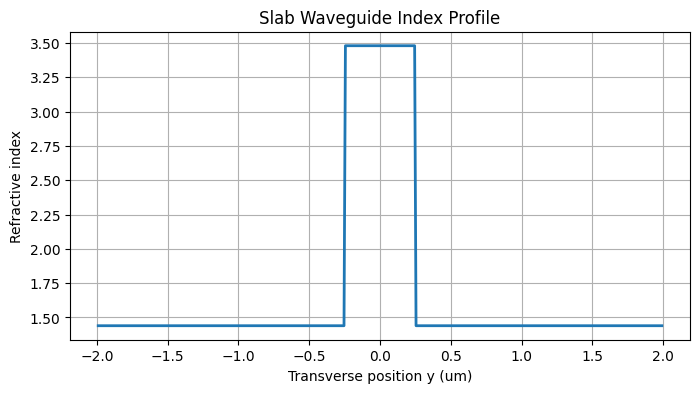

In [2]:
n = np.ones(ny) * n_clad

n[np.abs(y) <= width / 2] = n_core

plt.figure(figsize=(8, 4))

plt.plot(y, n, linewidth=2)

plt.xlabel("Transverse position y (um)")
plt.ylabel("Refractive index")
plt.title("Slab Waveguide Index Profile")

plt.grid(True)
plt.show()

In [3]:
main_diag = -2 * np.ones(ny)

off_diag = np.ones(ny - 1)

Dyy = sp.diags(
    [off_diag, main_diag, off_diag],
    [-1, 0, 1],
    shape=(ny, ny),
    format="csr"
) / dy**2

H = Dyy + k0**2 * sp.diags(
    n**2,
    format="csr"
)

print("Operator shape:", H.shape)
print("Nonzero entries:", H.nnz)

Operator shape: (400, 400)
Nonzero entries: 1198


In [4]:
# Calculate the six largest eigenvalues
eigenvalues, eigenvectors = spla.eigsh(
    H,
    k=6,
    which="LA"
)

# Sort in descending order
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

beta = np.sqrt(
    np.maximum(eigenvalues, 0)
)

n_eff = beta / k0

print("Effective indices:")

for i, value in enumerate(n_eff):
    print(f"Mode {i}: n_eff = {value:.6f}")

Effective indices:
Mode 0: n_eff = 3.275044
Mode 1: n_eff = 2.610265
Mode 2: n_eff = 1.447616
Mode 3: n_eff = 1.370853
Mode 4: n_eff = 1.316840
Mode 5: n_eff = 1.141092


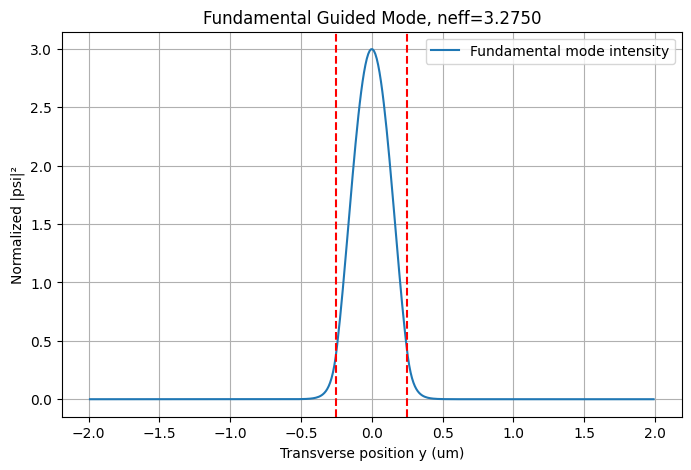

In [5]:
psi = eigenvectors[:, 0]

# Normalize
psi = psi / np.sqrt(
    np.sum(np.abs(psi)**2) * dy
)

plt.figure(figsize=(8, 5))

plt.plot(
    y,
    np.abs(psi)**2,
    label="Fundamental mode intensity"
)

plt.axvline(
    -width/2,
    color="red",
    linestyle="--"
)

plt.axvline(
    width/2,
    color="red",
    linestyle="--"
)

plt.xlabel("Transverse position y (um)")
plt.ylabel("Normalized |psi|²")

plt.title(
    f"Fundamental Guided Mode, neff={n_eff[0]:.4f}"
)

plt.legend()
plt.grid(True)
plt.show()

In [6]:
from scipy.optimize import brentq

def dispersion_even(neff):

    beta = k0 * neff

    h = np.sqrt(
        k0**2 * n_core**2 - beta**2
    )

    q = np.sqrt(
        beta**2 - k0**2 * n_clad**2
    )

    return h * np.tan(h * width / 2) - q


# Find the fundamental even-mode root.
# A dense scan avoids assuming a valid
# sign-changing interval near a tangent pole.

neff_scan = np.linspace(
    n_clad + 1e-6,
    n_core - 1e-6,
    10000
)

roots = []

for a, b in zip(
    neff_scan[:-1],
    neff_scan[1:]
):

    ha = k0 * np.sqrt(n_core**2 - a**2)
    hb = k0 * np.sqrt(n_core**2 - b**2)

    # Restrict to fundamental even branch
    if max(ha, hb) * width / 2 >= np.pi / 2:
        continue

    fa = dispersion_even(a)
    fb = dispersion_even(b)

    if fa * fb < 0:

        root = brentq(
            dispersion_even,
            a,
            b
        )

        roots.append(root)

if not roots:
    raise RuntimeError("No fundamental even-mode root found")

neff_analytical = max(roots)

neff_numerical = n_eff[0]

relative_error = (
    abs(neff_numerical - neff_analytical)
    / abs(neff_analytical)
)

print("Analytical neff:", neff_analytical)
print("Numerical neff:", neff_numerical)
print("Relative error:", relative_error)

Analytical neff: 3.2756153221562645
Numerical neff: 3.2750437796839718
Relative error: 0.00017448400257100618


Ny= 100, dy=0.039604, neff=3.26279597, error=3.913572e-03
Ny= 200, dy=0.019900, neff=3.28697466, error=3.467850e-03
Ny= 400, dy=0.009975, neff=3.27504378, error=1.744840e-04
Ny= 800, dy=0.004994, neff=3.27527519, error=1.038365e-04
Ny=1200, dy=0.003331, neff=3.27537647, error=7.291693e-05


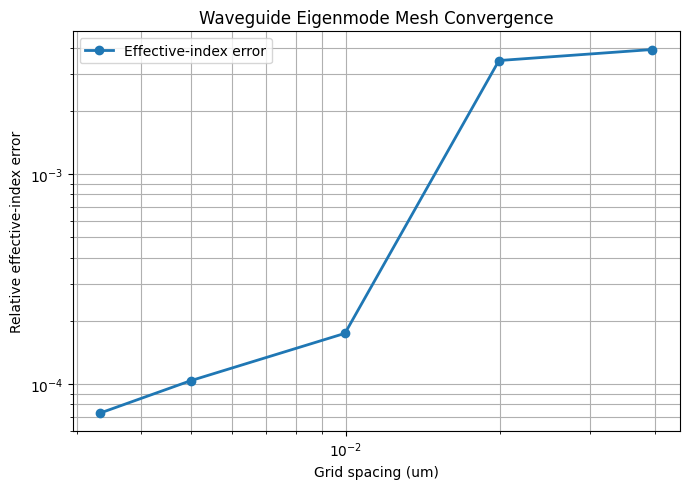

In [7]:
grid_sizes = [100, 200, 400, 800, 1200]

errors = []
spacings = []
numerical_indices = []

for ny_test in grid_sizes:

    dy_test = Ly / (ny_test + 1)

    y_test = (
        np.arange(1, ny_test + 1) * dy_test
        - Ly / 2
    )

    n_test = np.ones(ny_test) * n_clad

    n_test[
        np.abs(y_test) <= width / 2
    ] = n_core

    Dyy_test = sp.diags(
        [
            np.ones(ny_test - 1),
            -2 * np.ones(ny_test),
            np.ones(ny_test - 1)
        ],
        [-1, 0, 1],
        format="csr"
    ) / dy_test**2

    H_test = (
        Dyy_test
        + k0**2 * sp.diags(
            n_test**2,
            format="csr"
        )
    )

    eigenvalues_test, _ = spla.eigsh(
        H_test,
        k=1,
        which="LA"
    )

    beta_test = np.sqrt(eigenvalues_test[0])

    neff_test = beta_test / k0

    error = (
        abs(neff_test - neff_analytical)
        / neff_analytical
    )

    errors.append(error)
    spacings.append(dy_test)
    numerical_indices.append(neff_test)

    print(
        f"Ny={ny_test:4d}, "
        f"dy={dy_test:.6f}, "
        f"neff={neff_test:.8f}, "
        f"error={error:.6e}"
    )


plt.figure(figsize=(7, 5))

plt.loglog(
    spacings,
    errors,
    "o-",
    linewidth=2,
    label="Effective-index error"
)

plt.xlabel("Grid spacing (um)")
plt.ylabel("Relative effective-index error")

plt.title("Waveguide Eigenmode Mesh Convergence")

plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
n[np.abs(y) <= width / 2] = n_core

In [9]:
def subpixel_permittivity(
    y, dy, width, n_core, n_clad
):
    """
    Compute cell-averaged permittivity
    for a centered slab waveguide.
    """

    eps_core = n_core**2
    eps_clad = n_clad**2

    # Cell boundaries
    cell_left = y - dy / 2
    cell_right = y + dy / 2

    # Physical slab boundaries
    core_left = -width / 2
    core_right = width / 2

    # Length of intersection between
    # each cell and the slab
    overlap = np.maximum(
        0.0,
        np.minimum(cell_right, core_right)
        - np.maximum(cell_left, core_left)
    )

    # Core fraction
    fraction = overlap / dy

    # Averaged permittivity
    eps_avg = (
        fraction * eps_core
        + (1 - fraction) * eps_clad
    )

    return eps_avg

Ny= 100 | Standard=3.913572e-03 | Subpixel=3.649834e-04
Ny= 200 | Standard=3.467850e-03 | Subpixel=1.889634e-04
Ny= 400 | Standard=1.744840e-04 | Subpixel=4.067484e-05
Ny= 800 | Standard=1.038365e-04 | Subpixel=1.004509e-05
Ny=1200 | Standard=7.291693e-05 | Subpixel=4.444979e-06


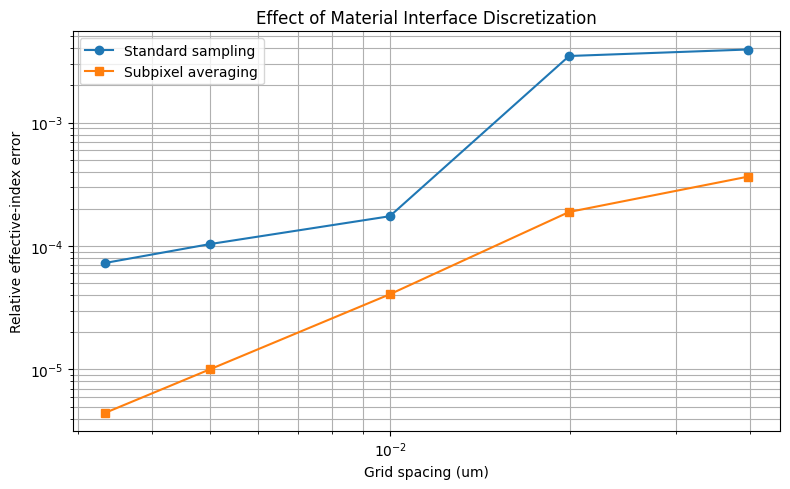

In [10]:
grid_sizes = [100, 200, 400, 800, 1200]

errors_standard = []
errors_subpixel = []
spacings = []

for ny_test in grid_sizes:

    dy_test = Ly / (ny_test + 1)

    y_test = (
        np.arange(1, ny_test + 1) * dy_test
        - Ly / 2
    )

    # Standard material assignment
    n_standard = np.ones(ny_test) * n_clad

    n_standard[
        np.abs(y_test) <= width / 2
    ] = n_core

    eps_standard = n_standard**2

    # Subpixel-averaged permittivity
    eps_subpixel = subpixel_permittivity(
        y_test,
        dy_test,
        width,
        n_core,
        n_clad
    )

    # Finite-difference operator
    Dyy_test = sp.diags(
        [
            np.ones(ny_test - 1),
            -2 * np.ones(ny_test),
            np.ones(ny_test - 1)
        ],
        [-1, 0, 1],
        format="csr"
    ) / dy_test**2

    def calculate_neff(eps_profile):

        H = (
            Dyy_test
            + k0**2 * sp.diags(
                eps_profile,
                format="csr"
            )
        )

        eigenvalue, _ = spla.eigsh(
            H,
            k=1,
            which="LA"
        )

        return np.sqrt(eigenvalue[0]) / k0

    neff_standard = calculate_neff(
        eps_standard
    )

    neff_subpixel = calculate_neff(
        eps_subpixel
    )

    error_standard = (
        abs(neff_standard - neff_analytical)
        / neff_analytical
    )

    error_subpixel = (
        abs(neff_subpixel - neff_analytical)
        / neff_analytical
    )

    errors_standard.append(error_standard)
    errors_subpixel.append(error_subpixel)
    spacings.append(dy_test)

    print(
        f"Ny={ny_test:4d} | "
        f"Standard={error_standard:.6e} | "
        f"Subpixel={error_subpixel:.6e}"
    )


plt.figure(figsize=(8, 5))

plt.loglog(
    spacings,
    errors_standard,
    "o-",
    label="Standard sampling"
)

plt.loglog(
    spacings,
    errors_subpixel,
    "s-",
    label="Subpixel averaging"
)

plt.xlabel("Grid spacing (um)")
plt.ylabel("Relative effective-index error")

plt.title(
    "Effect of Material Interface Discretization"
)

plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

In [11]:
import numpy as np

errors = np.array([
    3.649834e-4,
    1.889634e-4,
    4.067484e-5,
    1.004509e-5,
    4.444979e-6
])

ny_values = np.array([100, 200, 400, 800, 1200])

h = 4.0 / (ny_values + 1)

for i in range(len(h) - 1):

    p = np.log(errors[i] / errors[i+1]) / \
        np.log(h[i] / h[i+1])

    print(
        f"{ny_values[i]} -> {ny_values[i+1]}: "
        f"order = {p:.4f}"
    )

100 -> 200: order = 0.9566
200 -> 400: order = 2.2239
400 -> 800: order = 2.0213
800 -> 1200: order = 2.0129


In [12]:
n[np.abs(y) <= width / 2] = n_core